# Problem 3.8

Reproduce the solution of Ex. 3.8 and then try different initial guesses. Can you define a distinct region from where Newton's method converges?

In [7]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [8]:
# define Ex 3-8

def residuals(u):
    u1, u2 = u
    return np.array([
        u2 - 1/u1,
        u2 - np.sqrt(u1),
    ])

def jacobian(u):
    u1, u2 = u
    return np.array([
        [1/u1**2,            1],
        [-1/(2*np.sqrt(u1)), 1],
    ])

def solve_system(u0, max_iter=10, tol=1e-7, table=True):
    u = u0
    history = []  # (iteration, u1, u2, residual)
    converged = False
    for i in range(max_iter):
        r = residuals(u)
        J = jacobian(u)
        du = np.linalg.solve(J, -r)
        history.append((i, u[0], u[1], np.linalg.norm(r)))
        if np.linalg.norm(du) < tol:  # convergence criterion
            converged = True
            break
        u = u + du
    
    if table:
        print(f"{'iter':>4} {'u1':>16} {'u2':>16} {'||r||':>12}")
        for i_k, u_1k, u_2k, r_k in history:
            print(f"{i_k:4d} {u_1k:>16e} {u_2k:>16e} {r_k:12.4e}")
        print(f"{'converged' if converged else 'NOT converged'} after {i} iterations, u1 = {u[0]:.6e}, u2 = {u[1]:.6e}")

    return u, history, converged

u, history, converged = solve_system(np.array([2.0, 3.0])) # example run

iter               u1               u2        ||r||
   0     2.000000e+00     3.000000e+00   2.9605e+00
   1     4.852814e-01     8.786797e-01   1.1959e+00
   2     7.600637e-01     8.938464e-01   4.2241e-01
   3     9.526685e-01     9.822781e-01   6.7692e-02
   4     9.982886e-01     9.994172e-01   2.3133e-03
   5     9.999978e-01     9.999993e-01   2.9540e-06
   6     1.000000e+00     1.000000e+00   4.8690e-12
converged after 6 iterations, u1 = 1.000000e+00, u2 = 1.000000e+00


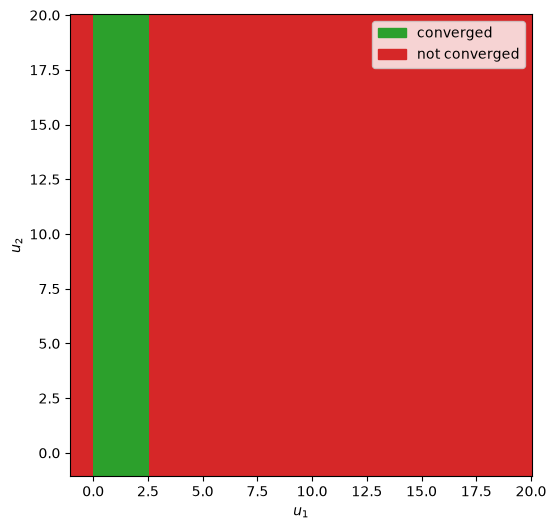

In [9]:
# plot the convergence region
import io
from contextlib import redirect_stdout
from matplotlib.colors import ListedColormap

def converged_at(u0):
    try:
        with redirect_stdout(io.StringIO()):       # silence the per-call printing
            _, _, converged = solve_system(u0, max_iter=100, table=False)
    except np.linalg.LinAlgError:                  # singular Jacobian
        return False
    return converged

axis = np.linspace(-1.0, 20.0, 200)
g1, g2 = np.meshgrid(axis, axis)
with np.errstate(all="ignore"):
    ok = np.array([converged_at(p) for p in np.column_stack([g1.ravel(), g2.ravel()])]).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pcolormesh(g1, g2, ok, cmap=ListedColormap(["tab:red", "tab:green"]), shading="auto")
ax.set_xlabel("$u_1$")
ax.set_ylabel("$u_2$")
ax.set_aspect("equal")
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="tab:green", label="converged"),
        plt.Rectangle((0, 0), 1, 1, color="tab:red", label="not converged"),
    ],
    loc="upper right",
)
plt.show()


## Results

as seen from the plot the newton solver converges for all u1 = (0, 2.5198). if u1 < 0 then the root function contains a negative number and numpy throws an error. if u1 = 0 the residual divides by 0 and the function also cant be evaluated. if u1 > 2.5198 then it also does not converge because then the next u1 is negative and then sqrt(u1) is undefined again.  
if i subtract the two equations form each other u2 cancels out and we are left wir a single residual with a set of strips in the u1,u2 plane that converge

## Interpretation

checking the fesible region for which there are valid solutions to the problem is important. the solver needs a good starting point. this can cause problems if the optimizer wants to run a combination of variables for which there is no valuid output. this can be avoided by setting bouding constraints for the variables and dhte optimizer needs to respect those limits.